In [19]:
import pandas as pd
import numpy as np
import sklearn
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from xgboost import XGBRegressor
import os
from pathlib import Path
import yaml

In [22]:
#Load data processed
project_dir = Path.cwd().parent

# Load config from folder data
with open(f'{project_dir}\\src\\features\\config.yaml', "r") as f:
    config = yaml.safe_load(f)

# Processed configuration
fileNameProc = config['fileNames']['processed']
fileTypeProc = config['fileTypes']['processed']
pathProc = project_dir.joinpath(config['paths']['processed_data'])

In [3]:
# class TranformData(BaseEstimator, TransformerMixin):
#     def __init__(self):
#         pass

#     def fit(self, X, y=None):
#         return self

#     def transform(self, X):
#         X = X.copy()

#         return X

In [23]:
# Read data
df = pd.read_parquet(f'{pathProc}\\{fileNameProc}.parquet')
df.head()

,Origen_Id,fecha_hora,demanda,lag_1h,lag_2h,lag_6h,lag_12h,lag_24h,lag_7d,media_24h,...,es_fin_semana,mes_sin,mes_cos,dia_mes,rolling_max_6h,rolling_max_12h,rolling_max_24h,origin_avg,origin_std,origin_max
168,10,2025-01-08 00:00:00,0,0.0,0.0,0.0,1.0,0.0,0.0,1.958333,...,0,0.5,0.866025,8,0.0,0.0,0.0,0.0,0.0,0.0
169,10,2025-01-08 01:00:00,0,0.0,0.0,0.0,3.0,0.0,0.0,1.958333,...,0,0.5,0.866025,8,0.0,0.0,0.0,0.0,0.0,0.0
170,10,2025-01-08 02:00:00,0,0.0,0.0,0.0,3.0,0.0,0.0,1.958333,...,0,0.5,0.866025,8,0.0,0.0,0.0,0.0,0.0,0.0
171,10,2025-01-08 03:00:00,0,0.0,0.0,0.0,4.0,0.0,0.0,1.958333,...,0,0.5,0.866025,8,0.0,0.0,0.0,0.0,0.0,0.0
172,10,2025-01-08 04:00:00,0,0.0,0.0,0.0,2.0,0.0,0.0,1.958333,...,0,0.5,0.866025,8,0.0,0.0,0.0,0.0,0.0,0.0


In [24]:
for col in df.select_dtypes(include=["int64"]):
    df[col] = pd.to_numeric(df[col], downcast="integer")

for col in df.select_dtypes(include=["float64"]):
    df[col] = pd.to_numeric(df[col], downcast="float")

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7147968 entries, 168 to 7227263
Data columns (total 24 columns):
 #   Column           Dtype         
---  ------           -----         
 0   Origen_Id        object        
 1   fecha_hora       datetime64[ns]
 2   demanda          int16         
 3   lag_1h           float32       
 4   lag_2h           float32       
 5   lag_6h           float32       
 6   lag_12h          float32       
 7   lag_24h          float32       
 8   lag_7d           float32       
 9   media_24h        float32       
 10  hour_sin         float32       
 11  hour_cos         float32       
 12  dow_sin          float32       
 13  dow_cos          float32       
 14  es_fin_semana    int8          
 15  mes_sin          float32       
 16  mes_cos          float32       
 17  dia_mes          int32         
 18  rolling_max_6h   float32       
 19  rolling_max_12h  float32       
 20  rolling_max_24h  float32       
 21  origin_avg       float32       
 2

# Test Split y transformar

In [26]:
TRAIN_SPLIT = 0.80   # 80% train, 20% test

# Ordenar por fecha
demanda_modelo = df.sort_values("fecha_hora").copy()

# Fechas únicas ordenadas: así no separas una misma hora entre train y test
fechas_unicas = demanda_modelo["fecha_hora"].drop_duplicates().sort_values()

# Posición de corte
indice_corte = int(len(fechas_unicas) * TRAIN_SPLIT)

# Fecha a partir de la cual inicia test
fecha_corte = fechas_unicas.iloc[indice_corte]

# Split temporal
train = demanda_modelo[
    demanda_modelo["fecha_hora"] < fecha_corte
].copy()

test = demanda_modelo[
    demanda_modelo["fecha_hora"] >= fecha_corte
].copy()

print("Fecha de corte:", fecha_corte)
print(f"Train: {train['fecha_hora'].min()} a {train['fecha_hora'].max()}")
print(f"Test:  {test['fecha_hora'].min()} a {test['fecha_hora'].max()}")

print(f"% train: {len(train) / len(demanda_modelo):.2%}")
print(f"% test:  {len(test) / len(demanda_modelo):.2%}")

Fecha de corte: 2026-05-27 19:00:00
Train: 2025-01-08 00:00:00 a 2026-05-27 18:00:00
Test:  2026-05-27 19:00:00 a 2026-09-30 23:00:00
% train: 80.00%
% test:  20.00%


In [27]:
# Separacion de X y y
X_train = train.drop(columns=["demanda"])
y_train = train["demanda"]

X_test = test.drop(columns=["demanda"])
y_test = test["demanda"]

# Creacion de pipeline

In [28]:
categorical_features = X_train.select_dtypes('object').columns
numeric_features = X_train.select_dtypes('number').columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num",StandardScaler(), numeric_features),
        ("cat",OneHotEncoder(handle_unknown="ignore", sparse_output=True), categorical_features),
    ]
)


pipeline = Pipeline([
    ('Preprocessing', preprocessor),
    ('Model',XGBRegressor())
])

In [10]:
# pipeline.fit(X_train,y_train)

In [11]:
# from sklearn.metrics import (
#     mean_absolute_error,
#     mean_squared_error,
#     r2_score,
# )
# import numpy as np

# y_pred = pipeline.predict(X_test)

# mae = mean_absolute_error(y_test, y_pred)
# rmse = np.sqrt(mean_squared_error(y_test, y_pred))
# r2 = r2_score(y_test, y_pred)

# print(f"MAE : {mae:.2f}")
# print(f"RMSE: {rmse:.2f}")
# print(f"R²  : {r2:.4f}")

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', XGBRegressor(objective='reg:squarederror', device="cuda"))
])

param_grid = {
    'model__n_estimators': [500, 1000],
    'model__max_depth': [7, 10],
    'model__learning_rate': [0.03, 0.075],
    'model__subsample': [ 0.8, 1.0],
    'model__colsample_bytree': [0.7, 1.0],
    'model__min_child_weight': [3, 5]
}

search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_grid,
    n_iter=20,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    verbose=1
)

search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': [0.7, 1.0], 'model__learning_rate': [0.03, 0.075], 'model__max_depth': [7, 10], 'model__min_child_weight': [3, 5], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-valida

In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_pipeline = search.best_estimator_

y_pred = best_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE : {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.4f}")

MAE : 0.74
RMSE: 1.34
R²  : 0.6905


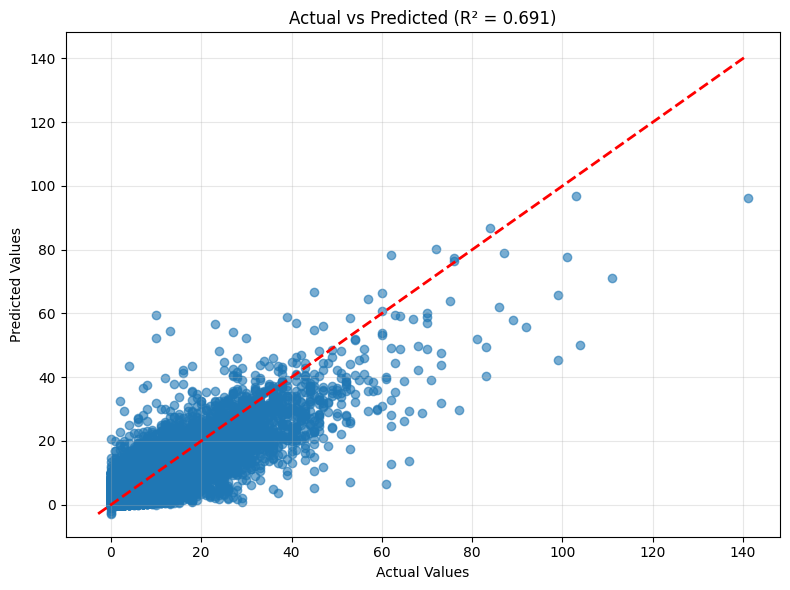

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Actual and predicted values
y_true = y_test
y_pred = best_pipeline.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_true, y_pred, alpha=0.6)

# Perfect prediction line
min_val = min(y_true.min(), y_pred.min())
max_val = max(y_true.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title(f"Actual vs Predicted (R² = {r2_score(y_true, y_pred):.3f})")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

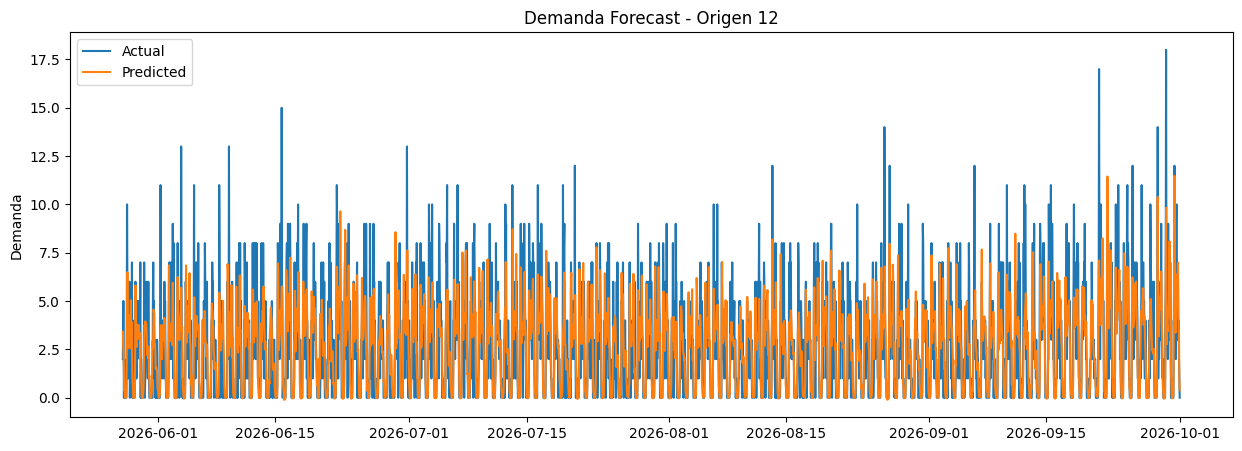

In [34]:
origen = '12'

mask = X_test['Origen_Id'] == origen

plt.figure(figsize=(15,5))

plt.plot(
    X_test.loc[mask, 'fecha_hora'],
    y_test[mask],
    label='Actual'
)

plt.plot(
    X_test.loc[mask, 'fecha_hora'],
    y_pred[mask],
    label='Predicted'
)

plt.title(f'Demanda Forecast - Origen {origen}')
plt.ylabel('Demanda')
plt.legend()
plt.show()